# IT3091 Bank Marketing · Member 4 (IT24100001)
## Part 1: Evaluation and Explainability of Member 3's tuned models

| Step | What happens |
|---|---|
| 0 | Mount Drive, find the saved files |
| 1 | Load the test data and the four tuned models |
| 2 | Test-set metrics, confusion matrices, ROC and PR curves, calibration |
| 3 | Explainability: permutation importance (all models), SHAP (one model), Logistic Regression odds ratios |
| 4 | Save results and figures for the report |

All results here use the default **0.5 threshold**, the same as Member 3. Threshold tuning comes in the next part.

## 0. Setup and file paths

In [ ]:
import os, sys, time, warnings, subprocess
warnings.filterwarnings("ignore")

def ensure(pkg):
    try:
        return __import__(pkg)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg])
        return __import__(pkg)

shap = ensure("shap"); ensure("lightgbm"); ensure("xgboost")

import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, brier_score_loss,
                             confusion_matrix, classification_report, roc_curve,
                             precision_recall_curve)
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance

RANDOM_STATE = 42
sns.set_style("whitegrid")
pd.set_option("display.width", 160)
print("scikit-learn:", sklearn.__version__, "| shap:", shap.__version__)

scikit-learn: 1.6.1 | shap: 0.52.0


In [ ]:
try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    pass  # running outside Colab

PROJECT_DIR  = os.environ.get("M4_PROJECT_DIR",
                              "/content/drive/MyDrive/ML & DWBI Assignment/ML Assignment")
MEMBER_3_DIR = os.path.join(PROJECT_DIR, "IT24102228")      # where Member 3 saved the models
MEMBER_4_DIR = os.path.join(PROJECT_DIR, "IT24100001")    # where this notebook saves
FIG_DIR      = os.path.join(MEMBER_4_DIR, "figures")
os.makedirs(FIG_DIR, exist_ok=True)

SEARCH_DIRS = [MEMBER_3_DIR, MEMBER_4_DIR,
               os.path.join(PROJECT_DIR, "IT24101461"), os.path.join(PROJECT_DIR, "IT24102060")]

def path(name):
    for d in SEARCH_DIRS:
        full = os.path.join(d, name)
        if os.path.exists(full):
            return full
    raise FileNotFoundError(f"{name} not found in: {SEARCH_DIRS}")

def save_fig(name):
    plt.savefig(os.path.join(FIG_DIR, name), dpi=150, bbox_inches="tight")

MODEL_FILES = {
    "Logistic Regression": "IT24102228_logistic_regression_tuned.joblib",
    "Random Forest":       "IT24102228_random_forest_tuned.joblib",
    "XGBoost":             "IT24102228_xgboost_tuned.joblib",
    "LightGBM":            "IT24102228_lightgbm_tuned.joblib",
}
for f in ["IT24101461_selected_data.joblib"] + list(MODEL_FILES.values()):
    try:
        print("found  ", os.path.relpath(path(f), PROJECT_DIR))
    except FileNotFoundError:
        print("MISSING", f)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
found   IT24102228/IT24101461_selected_data.joblib
found   IT24102228/IT24102228_logistic_regression_tuned.joblib
found   IT24102228/IT24102228_random_forest_tuned.joblib
found   IT24102228/IT24102228_xgboost_tuned.joblib
found   IT24102228/IT24102228_lightgbm_tuned.joblib


## 1. Load the test data and the models

The models were trained on Member 2's **30 processed columns** (scaled numbers and one-hot dummies), so we evaluate them on the same processed test set.



In [ ]:
X_train, X_test, y_train, y_test, selected_names = joblib.load(path("IT24101461_selected_data.joblib"))
y_test = np.asarray(y_test).astype(int)
feature_names = [str(n) for n in selected_names]

models = {name: joblib.load(path(f)) for name, f in MODEL_FILES.items()}

print("Test set:", X_test.shape, "| subscribers:", y_test.sum(), f"({y_test.mean():.2%})")
print("Models loaded:", list(models))

Test set: (9043, 30) | subscribers: 1058 (11.70%)
Models loaded: ['Logistic Regression', 'Random Forest', 'XGBoost', 'LightGBM']


In [ ]:
# Map each of the 30 model columns back to its original feature (e.g. month_mar -> month)
CATEGORICAL = ["job", "marital", "education", "default", "housing", "loan", "contact", "month",
               "poutcome", "age_group", "balance_group", "campaign_contact_group"]  # Member 2

def original_feature(col):
    base = col.split("__", 1)[1] if "__" in col else col
    matches = [c for c in CATEGORICAL if base.startswith(c + "_")]
    return max(matches, key=len) if matches else base

feature_map = pd.DataFrame({"model_column": feature_names,
                            "original_feature": [original_feature(c) for c in feature_names]})
feature_map.groupby("original_feature")["model_column"].apply(list).to_frame("model columns")

,model columns
original_feature,
age,[numeric__age]
age_group,"[categorical__age_group_18-30, categorical__ag..."
balance,[numeric__balance]
balance_group,[categorical__balance_group_low]
campaign,[numeric__campaign]
campaign_contact_group,[categorical__campaign_contact_group_first_con...
contact,"[categorical__contact_cellular, categorical__c..."
day,[numeric__day]
default,[categorical__default_no]


## 2. Test-set evaluation

### 2.1 Metrics table
Accuracy is shown, but with 88% "no" customers a model that always says "no" already gets 88%. **F1, PR-AUC and recall** tell the real story.

In [ ]:
probs = {name: m.predict_proba(X_test)[:, 1] for name, m in models.items()}
preds = {name: (p >= 0.5).astype(int) for name, p in probs.items()}

rows = []
for name in models:
    p, yhat = probs[name], preds[name]
    rows.append({"Model": name,
                 "Accuracy": accuracy_score(y_test, yhat),
                 "Precision": precision_score(y_test, yhat, zero_division=0),
                 "Recall": recall_score(y_test, yhat),
                 "F1": f1_score(y_test, yhat),
                 "ROC-AUC": roc_auc_score(y_test, p),
                 "PR-AUC": average_precision_score(y_test, p),
                 "Brier": brier_score_loss(y_test, p),
                 "Predicted yes": int(yhat.sum())})
results = pd.DataFrame(rows).set_index("Model").sort_values("F1", ascending=False)
print(f"Baselines: always-'no' accuracy = {1 - y_test.mean():.4f}, random PR-AUC = {y_test.mean():.4f}")
results.round(4)

Baselines: always-'no' accuracy = 0.8830, random PR-AUC = 0.1170


,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Brier,Predicted yes
Model,,,,,,,,
Random Forest,0.8722,0.4504,0.4206,0.4350,0.7800,0.4225,0.1079,988
LightGBM,0.8110,0.3298,0.5964,0.4248,0.7854,0.4328,0.1456,1913
Logistic Regression,0.7437,0.2599,0.6446,0.3705,0.7708,0.3947,0.1849,2624
XGBoost,0.8948,0.6490,0.2202,0.3289,0.7885,0.4319,0.0833,359


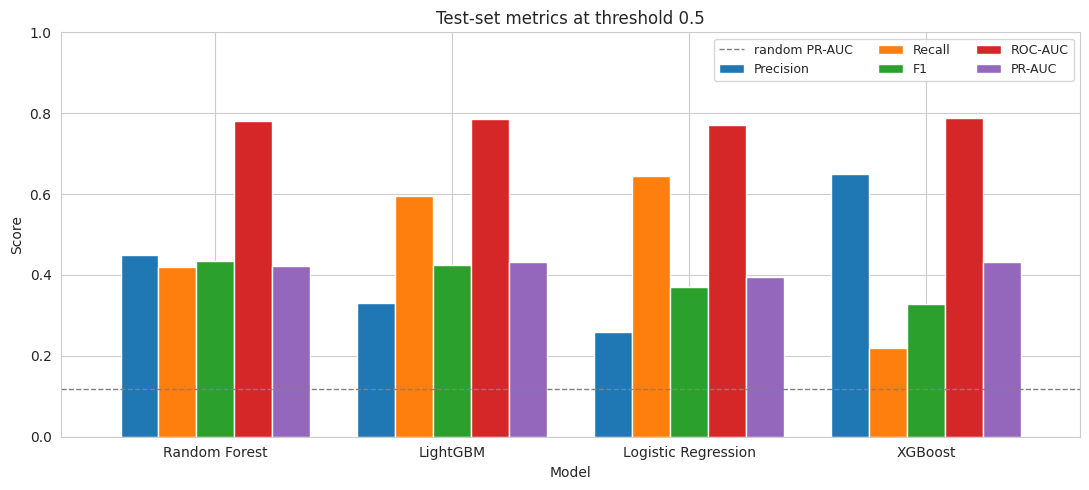

In [ ]:
metric_cols = ["Precision", "Recall", "F1", "ROC-AUC", "PR-AUC"]
ax = results[metric_cols].plot.bar(figsize=(11, 5), width=0.8, rot=0)
ax.axhline(y_test.mean(), color="grey", ls="--", lw=1, label="random PR-AUC")
ax.set_ylim(0, 1); ax.set_ylabel("Score"); ax.set_title("Test-set metrics at threshold 0.5")
ax.legend(ncol=3, fontsize=9)
plt.tight_layout(); save_fig("01_metrics_comparison.png"); plt.show()

**Reading it:** models with class weighting (Logistic Regression, LightGBM, Random Forest) trade precision for recall. XGBoost has no class weighting, so at 0.5 it says "yes" rarely: high precision, very low recall. Compare **ROC-AUC and PR-AUC** to see ranking quality independent of the threshold.

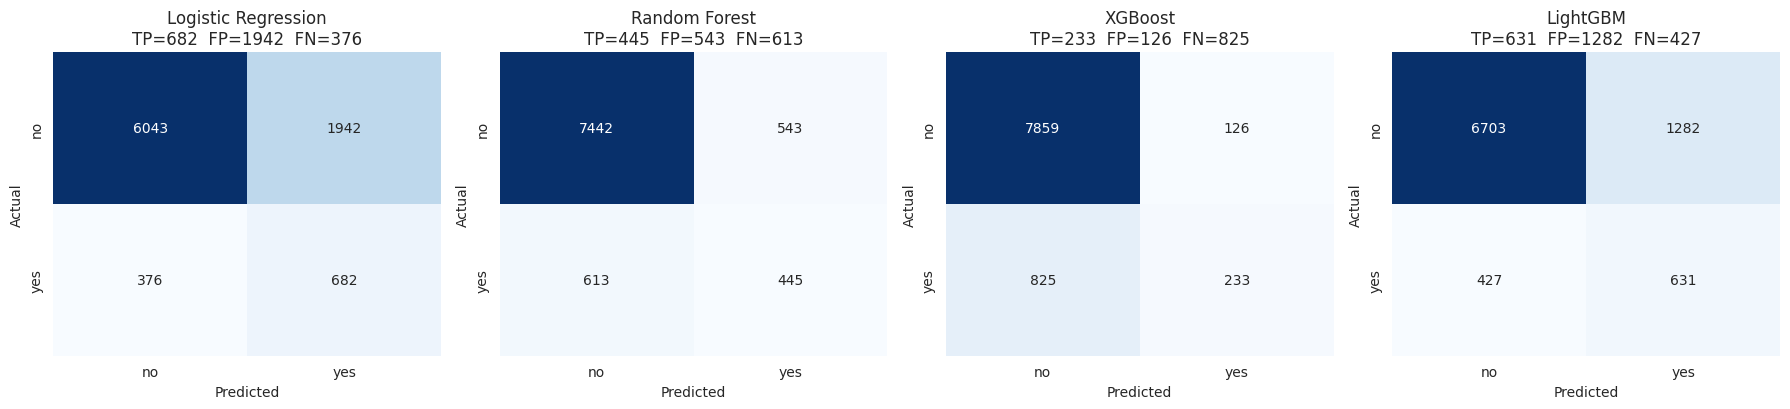

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4.2))
for ax, name in zip(axes, models):
    cm = confusion_matrix(y_test, preds[name])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["no", "yes"], yticklabels=["no", "yes"])
    tn, fp, fn, tp = cm.ravel()
    ax.set(title=f"{name}\nTP={tp}  FP={fp}  FN={fn}", xlabel="Predicted", ylabel="Actual")
plt.tight_layout(); save_fig("02_confusion_matrices.png"); plt.show()

| Cell | Business meaning |
|---|---|
| TP (actual yes, predicted yes) | Subscriber we would call: good |
| FP (actual no, predicted yes) | Wasted call |
| FN (actual yes, predicted no) | Subscriber we would miss |
| TN (actual no, predicted no) | Call correctly avoided |

In [ ]:
best_f1_model = results["F1"].idxmax()
print(f"Classification report: {best_f1_model} (highest test F1)\n")
print(classification_report(y_test, preds[best_f1_model], target_names=["no (0)", "yes (1)"], digits=4))

Classification report: Random Forest (highest test F1)

              precision    recall  f1-score   support

      no (0)     0.9239    0.9320    0.9279      7985
     yes (1)     0.4504    0.4206    0.4350      1058

    accuracy                         0.8722      9043
   macro avg     0.6872    0.6763    0.6815      9043
weighted avg     0.8685    0.8722    0.8703      9043



### 2.3 ROC and Precision-Recall curves

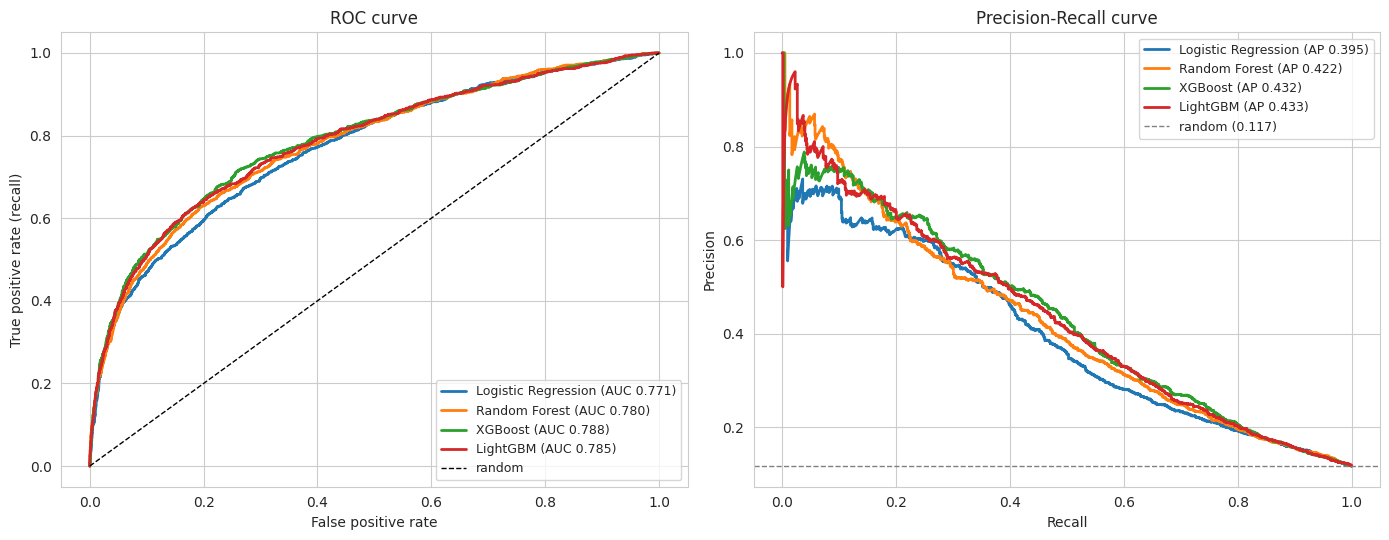

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for name, p in probs.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    prec, rec, _ = precision_recall_curve(y_test, p)
    axes[0].plot(fpr, tpr, lw=2, label=f"{name} (AUC {roc_auc_score(y_test, p):.3f})")
    axes[1].plot(rec, prec, lw=2, label=f"{name} (AP {average_precision_score(y_test, p):.3f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=1, label="random")
axes[0].set(xlabel="False positive rate", ylabel="True positive rate (recall)", title="ROC curve")
axes[1].axhline(y_test.mean(), color="grey", ls="--", lw=1, label=f"random ({y_test.mean():.3f})")
axes[1].set(xlabel="Recall", ylabel="Precision", title="Precision-Recall curve")
for ax in axes: ax.legend(fontsize=9)
plt.tight_layout(); save_fig("03_roc_pr_curves.png"); plt.show()

The PR curve is the more honest view for an imbalanced target: the ROC curve can look good even when precision on the rare "yes" class is low.

### 2.4 Calibration
Does a predicted probability of 0.3 really mean about 30% of those customers subscribe? Class weighting usually pushes probabilities **too high**.

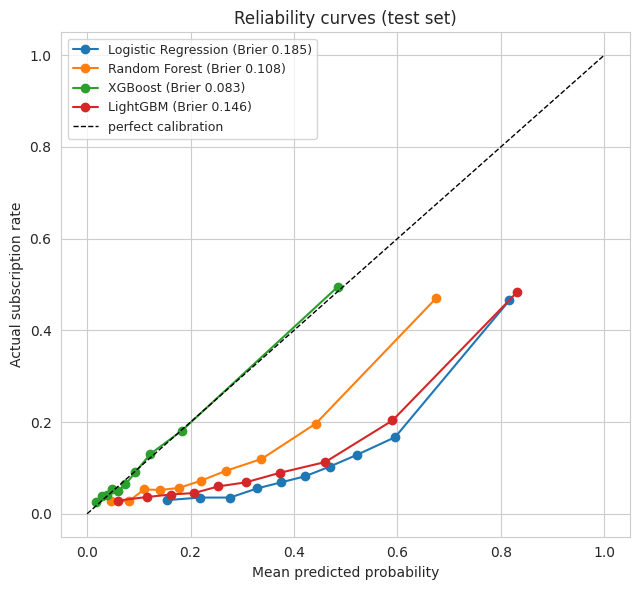

In [ ]:
fig, ax = plt.subplots(figsize=(6.5, 6))
for name, p in probs.items():
    frac_pos, mean_pred = calibration_curve(y_test, p, n_bins=10, strategy="quantile")
    ax.plot(mean_pred, frac_pos, "o-", label=f"{name} (Brier {brier_score_loss(y_test, p):.3f})")
ax.plot([0, 1], [0, 1], "k--", lw=1, label="perfect calibration")
ax.set(xlabel="Mean predicted probability", ylabel="Actual subscription rate",
       title="Reliability curves (test set)")
ax.legend(fontsize=9); plt.tight_layout(); save_fig("04_calibration.png"); plt.show()

## 3. Explainability

### 3.1 Permutation importance (all four models)
Shuffle one column at a time and measure how much **test PR-AUC** drops. Bigger drop = the model relies on that feature more. One-hot columns are summed back to their original feature.

In [ ]:
perm_results = {}
for name, model in models.items():
    t0 = time.time()
    r = permutation_importance(model, X_test, y_test, scoring="average_precision",
                               n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
    perm_results[name] = feature_map.assign(importance=r.importances_mean, std=r.importances_std)
    print(f"{name:<20} done in {time.time() - t0:.0f}s")

grouped = pd.DataFrame({name: df.groupby("original_feature")["importance"].sum()
                        for name, df in perm_results.items()})
grouped = grouped.loc[grouped.mean(axis=1).sort_values(ascending=False).index]
grouped.round(4)

Logistic Regression  done in 6s
Random Forest        done in 46s
XGBoost              done in 8s
LightGBM             done in 31s


,Logistic Regression,Random Forest,XGBoost,LightGBM
original_feature,,,,
previous_campaign_success,0.1356,0.0444,0.1014,0.1418
month,0.0405,0.0372,0.0548,0.0574
pdays_clean,0.0006,0.0399,0.0407,0.0452
contact,0.0166,0.0290,0.0318,0.0325
day,0.0020,0.0230,0.0312,0.0334
loan,0.0202,0.0136,0.0135,0.0225
poutcome,0.0024,0.0448,0.0010,-0.0006
age,0.0012,0.0056,0.0160,0.0170
balance,-0.0004,0.0154,0.0082,0.0135


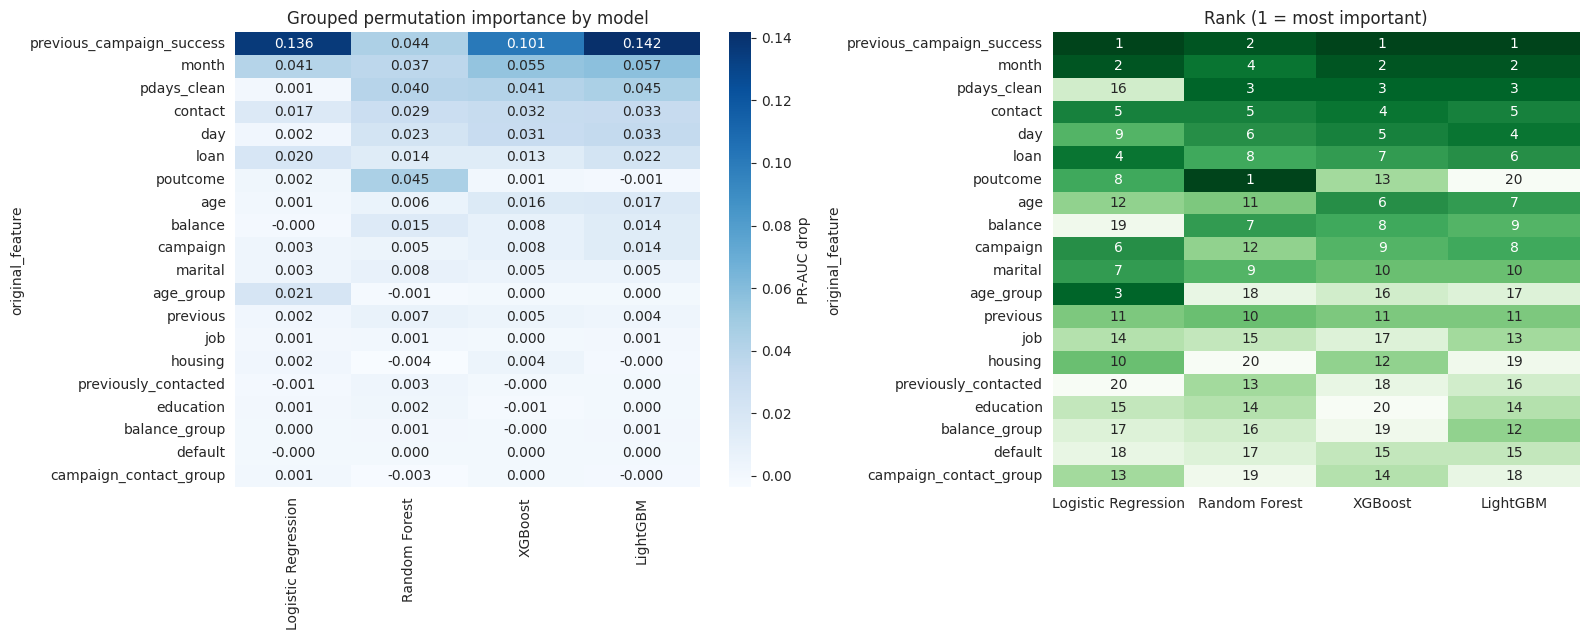

Top 5 features per model:
  Logistic Regression  previous_campaign_success, month, age_group, loan, contact
  Random Forest        poutcome, previous_campaign_success, pdays_clean, month, contact
  XGBoost              previous_campaign_success, month, pdays_clean, contact, day
  LightGBM             previous_campaign_success, month, pdays_clean, day, contact


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5), gridspec_kw={"width_ratios": [1.1, 1]})
sns.heatmap(grouped, annot=True, fmt=".3f", cmap="Blues", ax=axes[0], cbar_kws={"label": "PR-AUC drop"})
axes[0].set_title("Grouped permutation importance by model")

ranks = grouped.rank(ascending=False).astype(int)
sns.heatmap(ranks, annot=True, fmt="d", cmap="Greens_r", ax=axes[1], cbar=False)
axes[1].set_title("Rank (1 = most important)")
plt.tight_layout(); save_fig("05_permutation_importance_all_models.png"); plt.show()

print("Top 5 features per model:")
for name in grouped.columns:
    print(f"  {name:<20} {', '.join(grouped[name].nlargest(5).index)}")

**Reading it:** features that rank high for **all four** models are the robust drivers of subscription. A feature that matters to only one model is more likely a quirk of that model.

**Watch for duplicate features.** `previous_campaign_success` and `poutcome_success` carry the same information. When one is shuffled, the model still has the other, so importance gets **split** between them and one can look unimportant. Read them together when you write the report.

### 3.2 Logistic Regression odds ratios
Logistic Regression is directly interpretable. Each coefficient becomes an **odds ratio** = e^coefficient.

* Odds ratio 2.0: one standard deviation more (numeric) or having that category (dummy) **doubles** the odds of subscribing.
* Odds ratio 0.5: **halves** the odds.

Numeric inputs were standardised, so "one unit" means one standard deviation.

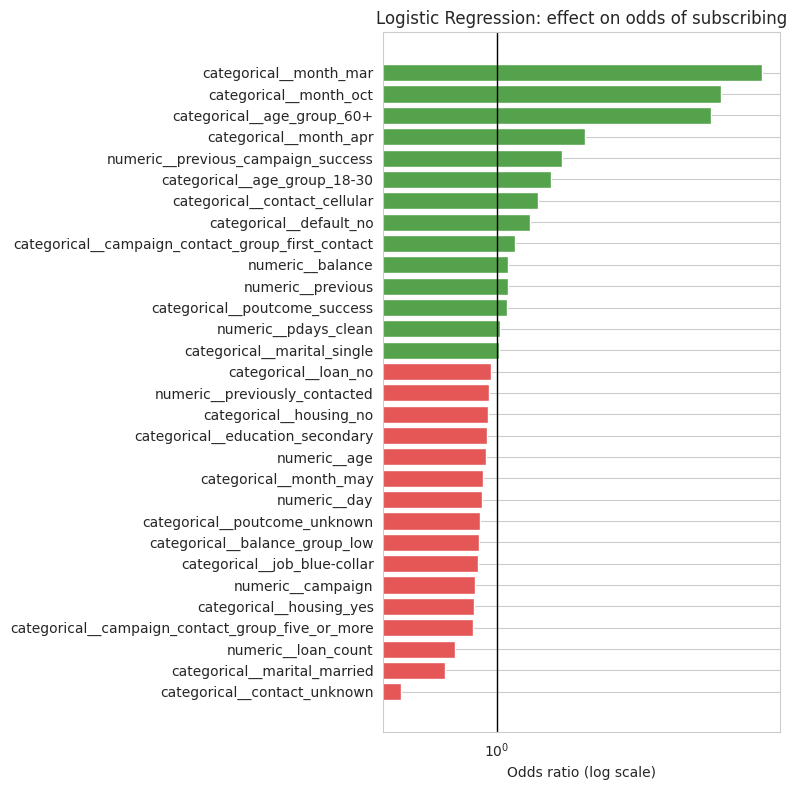

Strongest positive:
                      model_column  coefficient  odds_ratio
numeric__previous_campaign_success        0.394       1.482
            categorical__month_apr        0.531       1.700
        categorical__age_group_60+        1.296       3.656
            categorical__month_oct        1.353       3.868
            categorical__month_mar        1.602       4.961

Strongest negative:
                                    model_column  coefficient  odds_ratio
                    categorical__contact_unknown       -0.574       0.563
                    categorical__marital_married       -0.313       0.732
                             numeric__loan_count       -0.252       0.777
categorical__campaign_contact_group_five_or_more       -0.141       0.869
                        categorical__housing_yes       -0.138       0.871


In [ ]:
lr = models["Logistic Regression"]
lr_clf = lr.named_steps["classifier"] if hasattr(lr, "named_steps") else lr
odds = (pd.DataFrame({"model_column": feature_names, "coefficient": lr_clf.coef_[0]})
        .assign(odds_ratio=lambda d: np.exp(d.coefficient))
        .sort_values("odds_ratio"))

plt.figure(figsize=(8, 8))
colors = ["#E45756" if v < 1 else "#54A24B" for v in odds["odds_ratio"]]
plt.barh(odds["model_column"], odds["odds_ratio"], color=colors)
plt.axvline(1, color="black", lw=1)
plt.xscale("log"); plt.xlabel("Odds ratio (log scale)")
plt.title("Logistic Regression: effect on odds of subscribing")
plt.tight_layout(); save_fig("06_lr_odds_ratios.png"); plt.show()

print("Strongest positive:"); print(odds.tail(5).round(3).to_string(index=False))
print("\nStrongest negative:"); print(odds.head(5).round(3).to_string(index=False))

## 4. Save results for the report

In [ ]:
out = os.path.join(MEMBER_4_DIR, "IT24100001_part1_evaluation_explainability.joblib")
joblib.dump({"test_metrics": results, "permutation_grouped": grouped,
             "permutation_by_column": perm_results, "lr_odds_ratios": odds,
             "sklearn_version": sklearn.__version__}, out)
results.round(4).to_csv(os.path.join(MEMBER_4_DIR, "IT24100001_test_metrics.csv"))
grouped.round(4).to_csv(os.path.join(MEMBER_4_DIR, "IT24100001_permutation_importance.csv"))

print("Saved:", out)
print("Figures in", FIG_DIR)
for f in sorted(os.listdir(FIG_DIR)):
    print("  ", f)

Saved: /content/drive/MyDrive/ML & DWBI Assignment/ML Assignment/IT24100001/IT24100001_part1_evaluation_explainability.joblib
Figures in /content/drive/MyDrive/ML & DWBI Assignment/ML Assignment/IT24100001/figures
   01_metrics_comparison.png
   02_confusion_matrices.png
   03_roc_pr_curves.png
   04_calibration.png
   05_permutation_importance_all_models.png
   06_lr_odds_ratios.png


In [ ]:
print("=" * 64)
print("PART 1 SUMMARY")
print("=" * 64)
print(f"Best test F1 (at 0.5)  : {results['F1'].idxmax()} ({results['F1'].max():.4f})")
print(f"Best ROC-AUC           : {results['ROC-AUC'].idxmax()} ({results['ROC-AUC'].max():.4f})")
print(f"Best PR-AUC            : {results['PR-AUC'].idxmax()} ({results['PR-AUC'].max():.4f})")
print(f"Top drivers (all models, permutation): {', '.join(grouped.index[:5])}")
print(f"Top LR odds ratios (raise odds): {', '.join(odds.tail(3)['model_column'][::-1])}")

PART 1 SUMMARY
Best test F1 (at 0.5)  : Random Forest (0.4350)
Best ROC-AUC           : XGBoost (0.7885)
Best PR-AUC            : LightGBM (0.4328)
Top drivers (all models, permutation): previous_campaign_success, month, pdays_clean, contact, day
Top LR odds ratios (raise odds): categorical__month_mar, categorical__month_oct, categorical__age_group_60+
